In [ ]:
from google.colab import files

uploaded = files.upload()

Saving housing.csv to housing.csv


In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [ ]:
df = pd.read_csv("housing.csv")

In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


* # problem defintion


The goal is to use area characteristics such as location, income, number of rooms, population, and proximity to the ocean to **predict the median house value**. Since the target is a continuous numerical value, this is a **Supervised Learning → Regression** problem


* # Data Explore

In [ ]:
print("Shape:", df.shape)

Shape: (20640, 10)


In [ ]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


# The dataset contains 20,640 rows and 10 features. Most columns are numeric, while ocean_proximity is categorical. We also notice 207 missing values in total_bedrooms, so data preprocessing will be required before training the model.

In [ ]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# **Insight:**
The dataset shows a wide variation in housing and demographic features. The average median house value is about **$206,856**, while `median_income` has a mean of **3.87**. We also observe large differences between the minimum and maximum values, especially in `total_rooms`, `population`, and `households`, indicating potential outliers and different feature scales that may need preprocessing.


In [ ]:
df.columns.to_list()

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity']

In [ ]:
missing = df.isnull().sum()

missing[missing > 0]

,0
total_bedrooms,207



# The `total_bedrooms` feature contains **207 missing values** out of 20,640 rows. These missing values should be handled during preprocessing, for example by using **median imputation**, before training the model.


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()


# Duplicate rows can give some observations more weight than they should have, which may bias the model and affect its performance.


In [ ]:
df.dtypes

,0
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,object



The dataset contains **9 numerical features** stored as `float64` and **1 categorical feature**, `ocean_proximity`, stored as `object`. The categorical feature will need to be **encoded** before training the machine learning model.



# `Linear Regression` and `SGDRegressor` require numerical inputs, so the categorical feature `ocean_proximity` must be converted into numerical features using **One-Hot Encoding**. This allows the models to process the categorical information correctly.


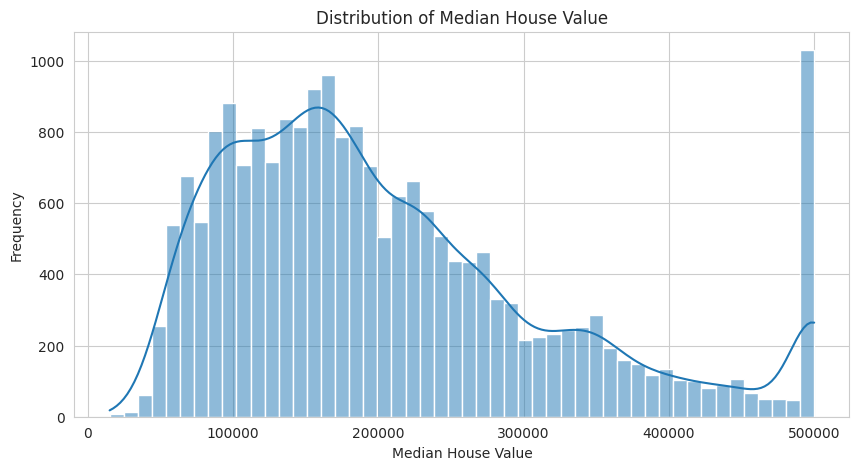

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

In [ ]:
df["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5



**The `ocean_proximity` feature has **5 categories**, with `<1H OCEAN` and `INLAND` being the most common. `ISLAND` appears only **5 times**, making it a very rare category that should be considered carefully during preprocessing and model evaluation.**


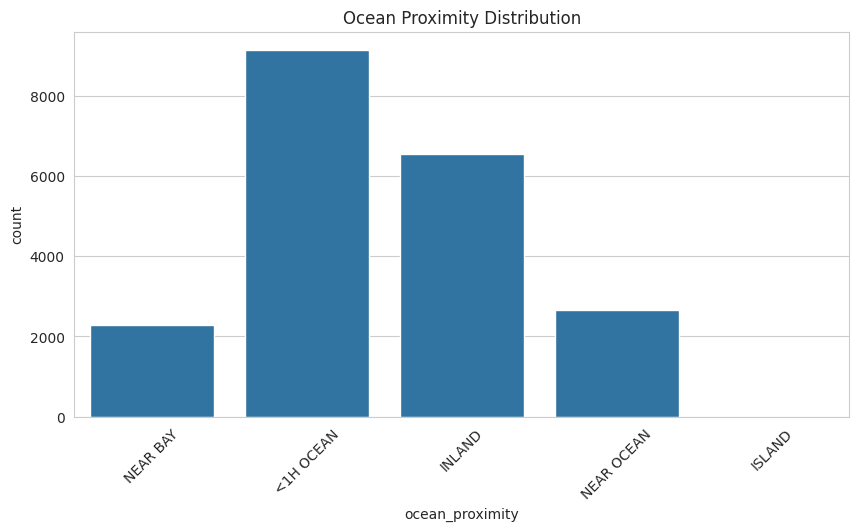

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="ocean_proximity"
)

plt.title("Ocean Proximity Distribution")
plt.xticks(rotation=45)

plt.show()

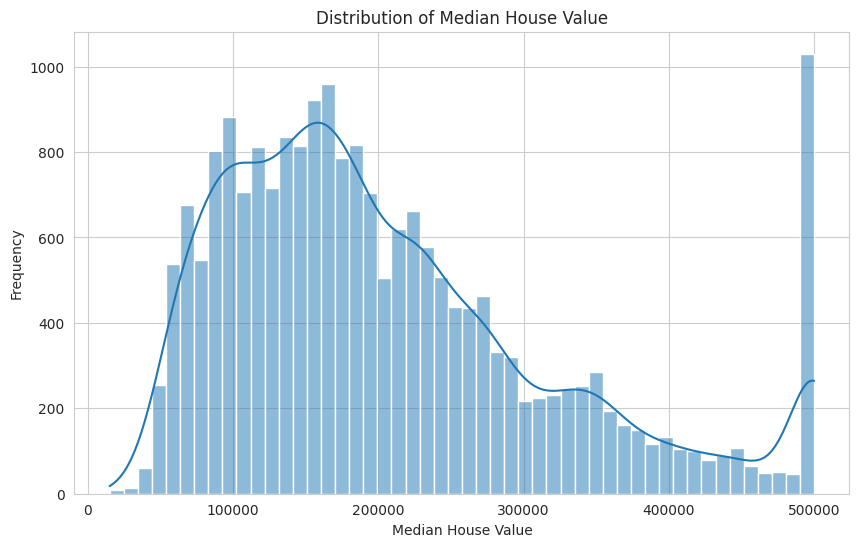

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

In [ ]:
target_skewness = df["median_house_value"].skew()

print("Target Skewness:", target_skewness)

Target Skewness: 0.9777632739098341


# **Insight:** `median_house_value` is right-skewed with a heavy upper tail, so extreme values may have a stronger impact on Linear Regression due to squared error.


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    print(f"\n{col}")
    print("Min:", df[col].min())
    print("Max:", df[col].max())


longitude
Min: -124.35
Max: -114.31

latitude
Min: 32.54
Max: 41.95

housing_median_age
Min: 1.0
Max: 52.0

total_rooms
Min: 2.0
Max: 39320.0

total_bedrooms
Min: 1.0
Max: 6445.0

population
Min: 3.0
Max: 35682.0

households
Min: 1.0
Max: 6082.0

median_income
Min: 0.4999
Max: 15.0001

median_house_value
Min: 14999.0
Max: 500001.0


** Most features have plausible ranges, but `total_rooms`, `population`, `households`, and `median_house_value` show large upper values that may indicate outliers or capped values and should be examined further.**


In [ ]:
checks = {
    "total_rooms <= 0": (df["total_rooms"] <= 0).sum(),
    "population <= 0": (df["population"] <= 0).sum(),
    "households <= 0": (df["households"] <= 0).sum(),
    "median_income <= 0": (df["median_income"] <= 0).sum(),
    "total_bedrooms <= 0": (df["total_bedrooms"] <= 0).sum()
}

pd.Series(checks)

,0
total_rooms <= 0,0
population <= 0,0
households <= 0,0
median_income <= 0,0
total_bedrooms <= 0,0


**  Before EDA, we should check for invalid zero or negative values, as they can lead to misleading ratios and unreliable results during Feature Engineering. **


In [ ]:
# Bedrooms should generally not exceed rooms
invalid_bedrooms = (
    df["total_bedrooms"] > df["total_rooms"]
).sum()

print(
    "Rows where bedrooms > rooms:",
    invalid_bedrooms
)

Rows where bedrooms > rooms: 0


In [ ]:
df_raw = df.copy()

In [ ]:
df_clean = df.copy()

In [ ]:
print("Dataset Shape:", df_clean.shape)
print("\nDuplicate Rows:", df_clean.duplicated().sum())

Dataset Shape: (20640, 10)

Duplicate Rows: 0


* # Outlier Detection

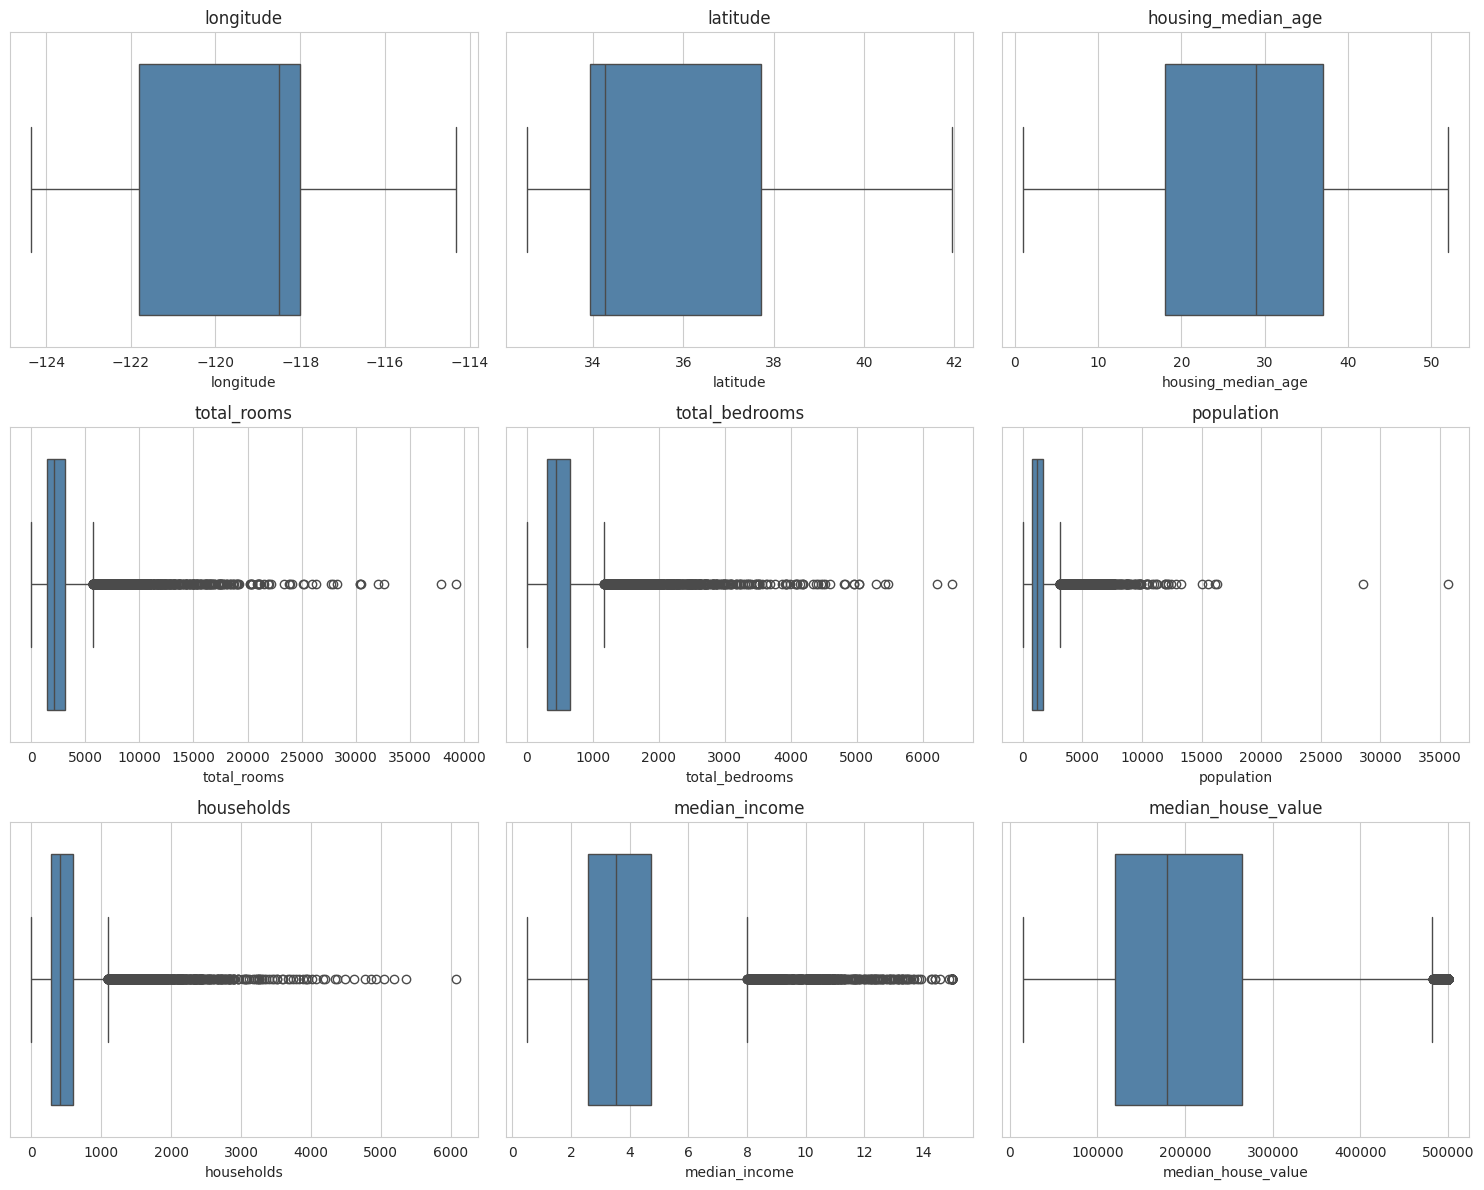

In [ ]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        x=df[col],
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col)

plt.tight_layout()
plt.show()

# **Insight:** Outliers will not be removed automatically, as extreme values may represent real high-density, high-income, or high-value areas. Their impact will be monitored through EDA, residual analysis, and model evaluation.


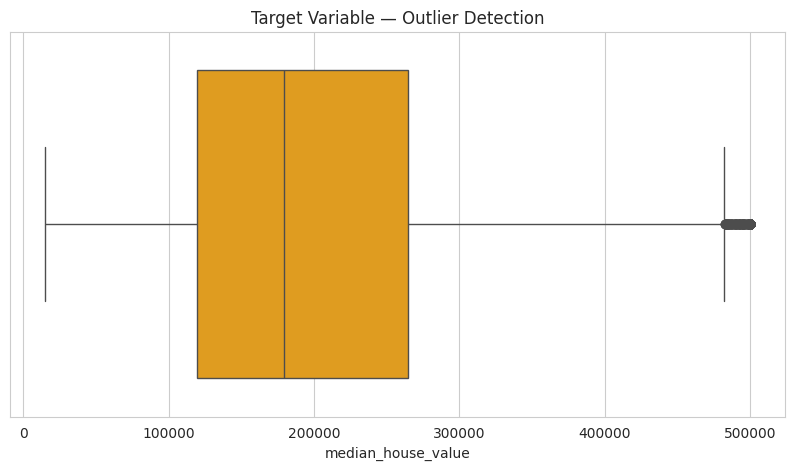

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["median_house_value"],
    color="orange"
)

plt.title("Target Variable — Outlier Detection")
plt.show()

In [ ]:
df["median_house_value"].quantile(
    [0.90, 0.95, 0.99, 0.995, 1.00]
)

,median_house_value
0.900,376600.0
0.950,489810.0
0.990,500001.0
0.995,500001.0
1.000,500001.0


# `median_house_value` has a heavy upper tail, with values reaching the maximum cap of **$500,001** from the 99th percentile onward. This indicates a clear ceiling effect in the target variable.


* # Missing Values Handling

In [ ]:
df_clean["total_bedrooms"].fillna(
    df_clean["total_bedrooms"].median()
)

,total_bedrooms
0,129.0
1,1106.0
2,190.0
3,235.0
4,280.0
...,...
20635,374.0
20636,150.0
20637,485.0
20638,409.0


In [ ]:
SimpleImputer(strategy="median")

SimpleImputer(strategy='median')

**We will keep the missing values for now, as imputation belongs in the modeling pipeline. The median will be calculated using the training data only to avoid data leakage.**


In [ ]:
# ==========================================
# CORRELATION WITH TARGET
# ==========================================

target_corr = (
    df_clean
    .select_dtypes(include=np.number)
    .corr()["median_house_value"]
    .sort_values(ascending=False)
)

target_corr

,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


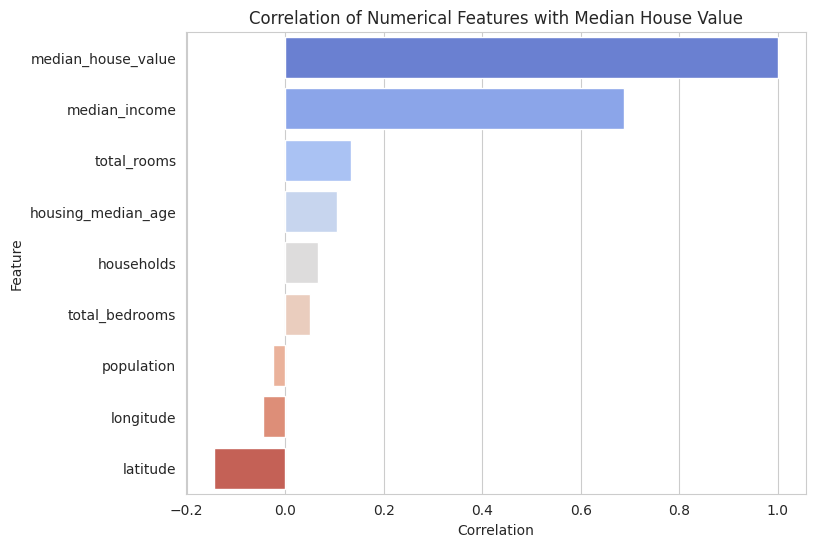

In [ ]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    palette="coolwarm"
)

plt.title("Correlation of Numerical Features with Median House Value")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()

**Positive correlation indicates that a feature tends to increase with house value, while negative correlation indicates the opposite. A correlation near zero suggests a weak linear relationship. However, correlation measures association, not causation, and a low correlation does not necessarily mean the feature is unimportant, especially when the relationship is nonlinear.**


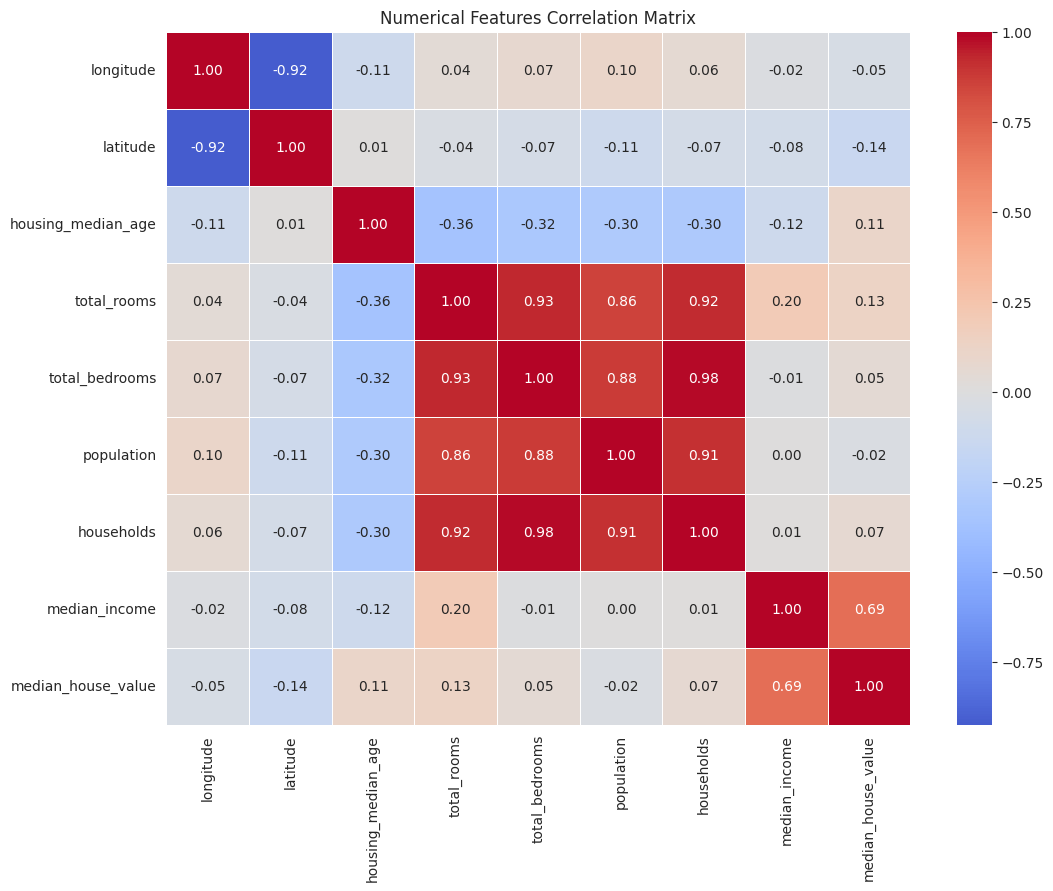

In [ ]:
corr_matrix = (
    df_clean
    .select_dtypes(include=np.number)
    .corr()
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Numerical Features Correlation Matrix")

plt.show()

The correlation matrix helps identify both feature–target relationships and **multicollinearity**. Highly correlated features may make it difficult for Linear Regression to distinguish their individual effects.



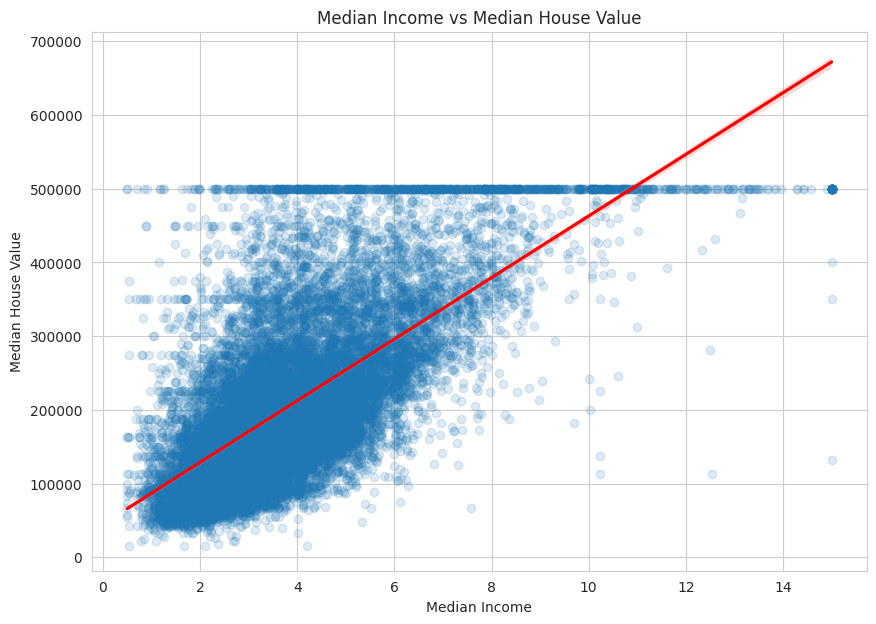

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=df_clean,
    x="median_income",
    y="median_house_value",
    scatter_kws={"alpha": 0.15},
    line_kws={"color": "red"}
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

# **Insight:** `median_income` shows strong predictive potential for `median_house_value`. A clear positive trend suggests substantial predictive information, while curvature or saturation may indicate a nonlinear relationship.


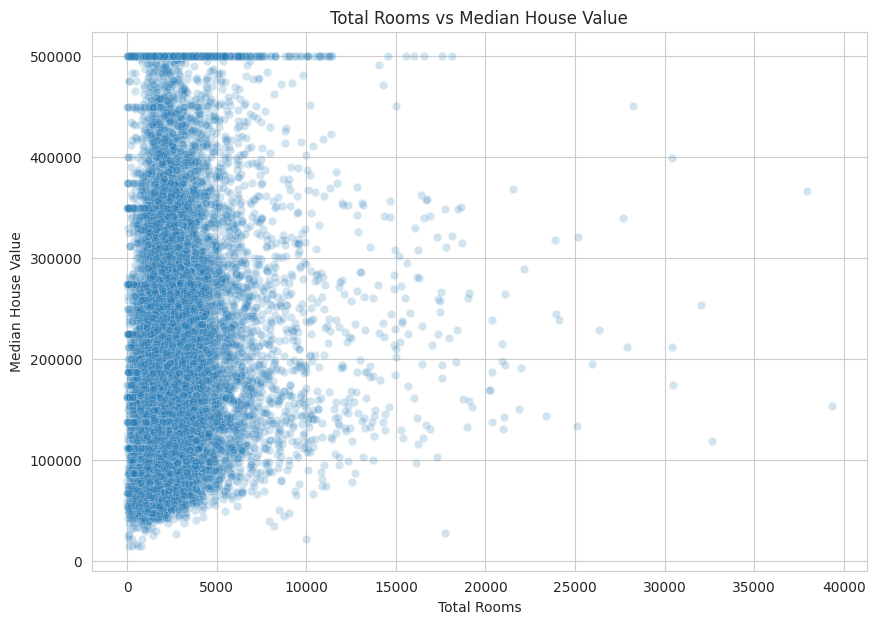

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_clean,
    x="total_rooms",
    y="median_house_value",
    alpha=0.2
)

plt.title("Total Rooms vs Median House Value")
plt.xlabel("Total Rooms")
plt.ylabel("Median House Value")

plt.show()

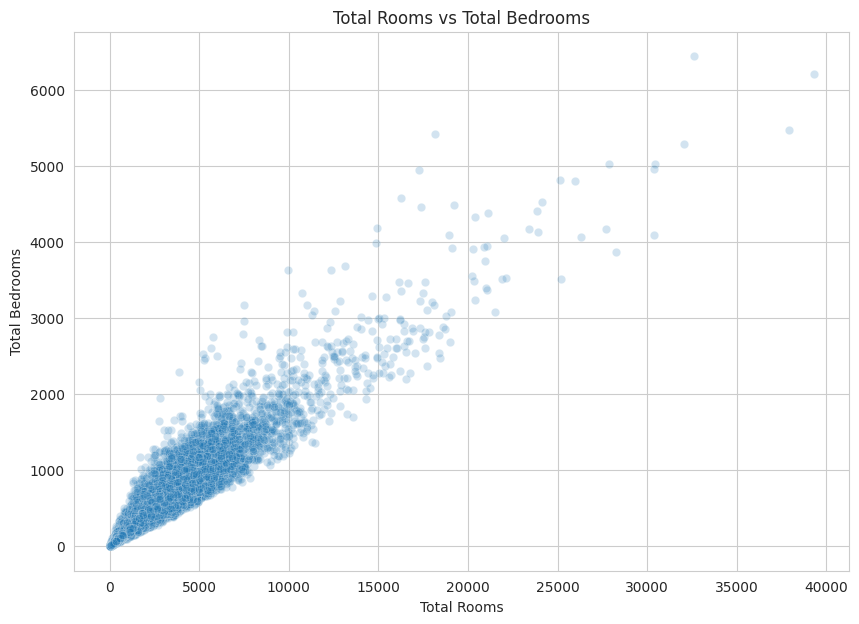

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_clean,
    x="total_rooms",
    y="total_bedrooms",
    alpha=0.2
)

plt.title("Total Rooms vs Total Bedrooms")
plt.xlabel("Total Rooms")
plt.ylabel("Total Bedrooms")

plt.show()

# **Insight:** The strong correlation between `total_rooms` and `total_bedrooms` suggests feature redundancy. A ratio such as `bedrooms_per_room` may capture more meaningful and interpretable information for the model.


In [ ]:
relationship_summary = pd.DataFrame({
    "Feature": target_corr.index,
    "Correlation_with_Target": target_corr.values
})

relationship_summary

,Feature,Correlation_with_Target
0,median_house_value,1.000000
1,median_income,0.688075
2,total_rooms,0.134153
3,housing_median_age,0.105623
4,households,0.065843
5,total_bedrooms,0.049686
6,population,-0.024650
7,longitude,-0.045967
8,latitude,-0.144160


# * # Feature Engineering

In [ ]:
df_model = df_clean.copy()

df_model["rooms_per_household"] = (
    df_model["total_rooms"] /
    df_model["households"]
)

In [ ]:
df_model["bedrooms_per_room"] = (
    df_model["total_bedrooms"] /
    df_model["total_rooms"]
)

In [ ]:
df_model["population_per_household"] = (
    df_model["population"] /
    df_model["households"]
)

In [ ]:
df_model[
    [
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333


In [ ]:
print(
    "Infinite values:",
    np.isinf(df_model.select_dtypes(include=np.number)).sum().sum()
)

Infinite values: 0


In [ ]:
new_features = [
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household"
]

engineered_corr = (
    df_model[
        new_features + ["median_house_value"]
    ]
    .corr()["median_house_value"]
    .sort_values(ascending=False)
)

engineered_corr

,median_house_value
median_house_value,1.000000
rooms_per_household,0.151948
population_per_household,-0.023737
bedrooms_per_room,-0.255880


**Insight:** Not every engineered feature should be included in the model. We will compare its added value against the original variables, with final performance on the test set determining whether it improves the model.


* # Define X and y

In [ ]:
X = df_model.drop(
    columns=["median_house_value"]
)

y = df_model["median_house_value"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

**Insight:** The test set will remain unseen and be used only to evaluate generalization. All learned parameters, such as imputation and scaling statistics, will be fitted on the training set only to prevent data leakage.


In [ ]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Categorical features:
['ocean_proximity']


In [ ]:
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [ ]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [ ]:
preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

**Insight:** Separating numerical and categorical preprocessing ensures that each data type receives the appropriate treatment. Putting all transformations into a Pipeline also keeps preprocessing consistent across training and test data.


In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)
print("Processed train shape:", X_train_processed.shape)
print("Processed test shape :", X_test_processed.shape)

Processed train shape: (16512, 16)
Processed test shape : (4128, 16)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Number of final features:", len(feature_names))

Number of final features: 16


In [ ]:
feature_names[:20]

array(['numeric__longitude', 'numeric__latitude',
       'numeric__housing_median_age', 'numeric__total_rooms',
       'numeric__total_bedrooms', 'numeric__population',
       'numeric__households', 'numeric__median_income',
       'numeric__rooms_per_household', 'numeric__bedrooms_per_room',
       'numeric__population_per_household',
       'categorical__ocean_proximity_<1H OCEAN',
       'categorical__ocean_proximity_INLAND',
       'categorical__ocean_proximity_ISLAND',
       'categorical__ocean_proximity_NEAR BAY',
       'categorical__ocean_proximity_NEAR OCEAN'], dtype=object)

* # Linear Regression

In [ ]:
linear_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

In [ ]:
linear_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income',
                                                   'rooms_per_household',
                                                   'bedrooms_per_room',
                                                   'population_per_household']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['ocean_proximity'])])),
                ('model', LinearRegression())])

In [ ]:
y_pred_lr = linear_model.predict(
    X_test
)

In [ ]:
def evaluate_regression(
    y_true,
    y_pred,
    model_name
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        y_pred
    )

    return pd.DataFrame({
        "Model": [model_name],
        "MAE": [mae],
        "MSE": [mse],
        "RMSE": [rmse],
        "R2": [r2]
    })

In [ ]:
lr_results = evaluate_regression(
    y_test,
    y_pred_lr,
    "Linear Regression"
)

lr_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,49645.492445,4.778547e+09,69127.038299,0.635339


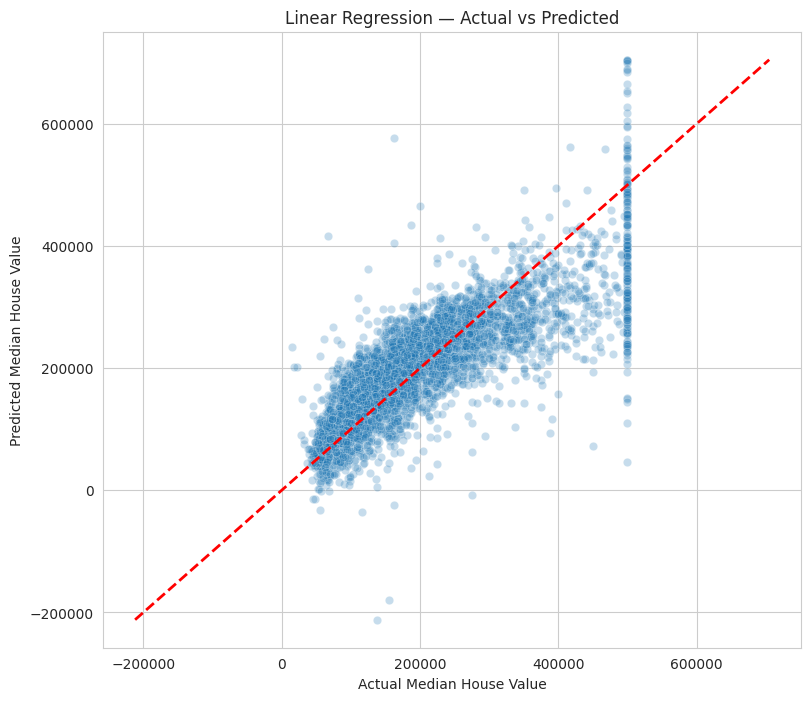

In [ ]:
plt.figure(figsize=(9, 8))

sns.scatterplot(
    x=y_test,
    y=y_pred_lr,
    alpha=0.25
)

min_value = min(
    y_test.min(),
    y_pred_lr.min()
)

max_value = max(
    y_test.max(),
    y_pred_lr.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")

plt.title(
    "Linear Regression — Actual vs Predicted"
)

plt.show()

* # SGD

In [ ]:
sgd_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        SGDRegressor(
            loss="squared_error",
            penalty="l2",
            alpha=0.0001,
            max_iter=2000,
            tol=1e-3,
            learning_rate="adaptive",
            eta0=0.01,
            random_state=42
        )
    )
])

In [ ]:
sgd_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income',
                                                   'rooms_per_household',
                                                   'bedrooms_per_room',
                                                   'population_per_household']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['ocean_proximity'])])),
                ('model',
                 SGDRegressor(learning_rate='adaptive', max_iter=2000,
                              random_state=42))])

In [ ]:
y_pred_sgd = sgd_model.predict(
    X_test
)

In [ ]:
sgd_results = evaluate_regression(
    y_test,
    y_pred_sgd,
    "SGD Regression"
)

sgd_results

,Model,MAE,MSE,RMSE,R2
0,SGD Regression,2.461422e+08,3.201838e+17,5.658479e+08,-2.443389e+07


In [ ]:
results = pd.concat(
    [
        lr_results,
        sgd_results
    ],
    ignore_index=True
)

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,4.964549e+04,4.778547e+09,6.912704e+04,6.353392e-01
1,SGD Regression,2.461422e+08,3.201838e+17,5.658479e+08,-2.443389e+07


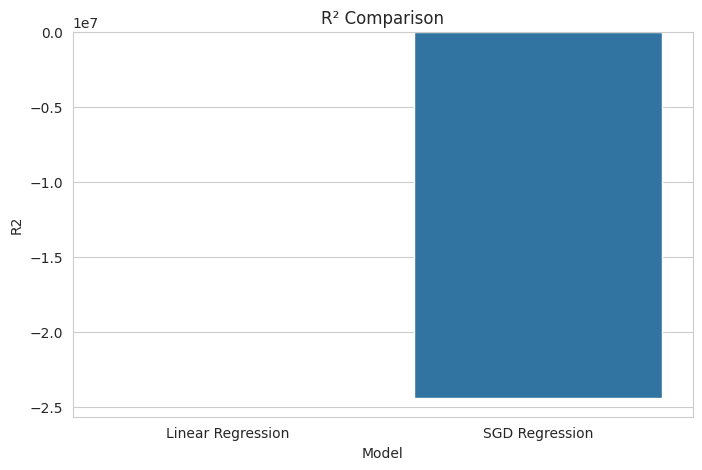

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2"
)

plt.title("R² Comparison")

plt.show()

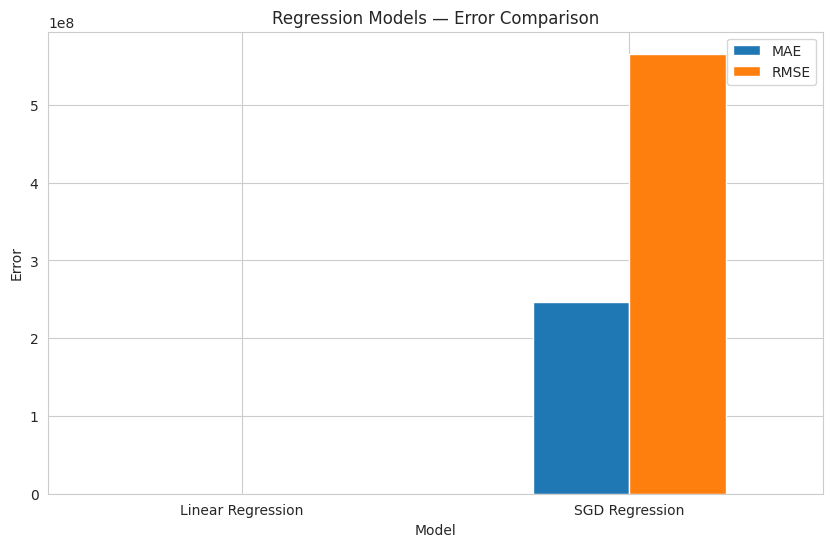

In [ ]:
results_plot = results.set_index("Model")

results_plot[
    ["MAE", "RMSE"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Regression Models — Error Comparison"
)

plt.ylabel("Error")
plt.xticks(rotation=0)

plt.show()

## Save the trained Linear Regression pipeline for Streamlit
Run this cell after the `linear_model.fit(...)` cell has completed successfully.

In [ ]:
import joblib
joblib.dump(linear_model, "linear_regression_pipeline.pkl")
print("Saved: linear_regression_pipeline.pkl")